# 01 - Exploratory Data Analysis
Bank Marketing campaign dataset (UCI / Kaggle). See `README.md` for the full
data source citation and project overview.

This notebook explores data quality, the target class balance, and how
subscription rate (`y`) varies across client attributes and campaign
mechanics - the questions a marketing analytics stakeholder actually asks
before any modeling happens.

In [1]:
import sys
sys.path.append('..')
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.data_cleaning import run as run_cleaning

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

df, quality_report = run_cleaning(save=True)
quality_report

{'rows_in': 41188,
 'duplicate_rows_dropped': 12,
 'rows_out': 41176,
 'unknown_value_counts': {'job': 330,
  'marital': 80,
  'education': 1730,
  'default': 8596,
  'housing': 990,
  'loan': 990,
  'poutcome': 0},
 'target_positive_rate': 0.11266271614532737}

## Shape, dtypes, and missingness (`unknown` placeholders)

In [2]:
print(f"Rows: {df.shape[0]:,}  Columns: {df.shape[1]}")
df.info()

Rows: 41,176  Columns: 21
<class 'pandas.core.frame.DataFrame'>
Index: 41176 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41176 non-null  int64  
 1   job             41176 non-null  object 
 2   marital         41176 non-null  object 
 3   education       41176 non-null  object 
 4   default         41176 non-null  object 
 5   housing         41176 non-null  object 
 6   loan            41176 non-null  object 
 7   contact         41176 non-null  object 
 8   month           41176 non-null  object 
 9   day_of_week     41176 non-null  object 
 10  duration        41176 non-null  int64  
 11  campaign        41176 non-null  int64  
 12  pdays           41176 non-null  int64  
 13  previous        41176 non-null  int64  
 14  poutcome        41176 non-null  object 
 15  emp_var_rate    41176 non-null  float64
 16  cons_price_idx  41176 non-null  float64
 17  cons_conf_

In [3]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41176.0,NaN,NaN,NaN,40.0238,10.42068,17.0,32.0,38.0,47.0,98.0
job,41176,12,admin.,10419,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41176,4,married,24921,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41176,8,university.degree,12164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41176,3,no,32577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41176,3,yes,21571,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41176,3,no,33938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41176,2,cellular,26135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41176,10,may,13767,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41176,5,thu,8618,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Target imbalance
Only ~11% of clients subscribed to a term deposit. This imbalance drives
every modeling choice downstream (class weighting, PR-AUC over accuracy,
threshold selection).

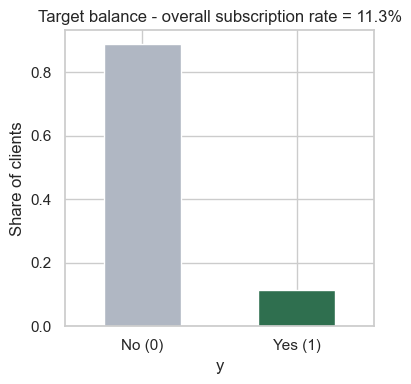

In [4]:
rate = df['y'].mean()
ax = df['y'].value_counts(normalize=True).sort_index().plot(
    kind='bar', color=['#b0b7c3', '#2f6f4f'], figsize=(4,4))
ax.set_xticklabels(['No (0)', 'Yes (1)'], rotation=0)
ax.set_ylabel('Share of clients')
ax.set_title(f'Target balance - overall subscription rate = {rate:.1%}')
plt.tight_layout()
plt.savefig('../reports/figures/target_balance.png', dpi=150)
plt.show()

## Subscription rate by demographic and campaign attributes

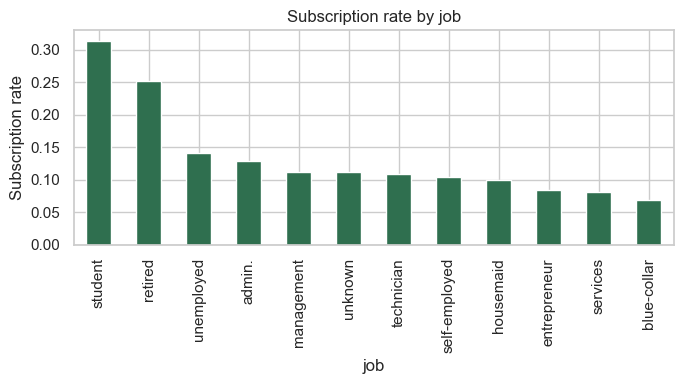

,mean,count
job,,
student,0.314286,875
retired,0.252619,1718
unemployed,0.142012,1014
admin.,0.129667,10419
management,0.112175,2924
unknown,0.112121,330
technician,0.108325,6739
self-employed,0.104856,1421
housemaid,0.100000,1060


In [5]:
def conversion_by(col, top_n=None, figsize=(7,4)):
    g = df.groupby(col)['y'].agg(['mean', 'count']).sort_values('mean', ascending=False)
    if top_n:
        g = g.head(top_n)
    ax = g['mean'].plot(kind='bar', color='#2f6f4f', figsize=figsize)
    ax.set_ylabel('Subscription rate')
    ax.set_title(f'Subscription rate by {col}')
    plt.tight_layout()
    plt.savefig(f'../reports/figures/conversion_by_{col}.png', dpi=150)
    plt.show()
    return g

conversion_by('job')

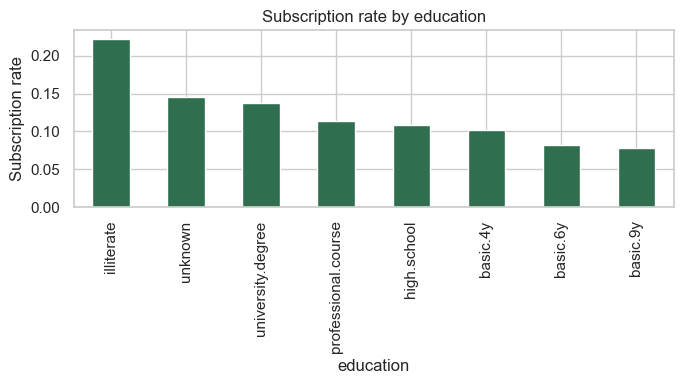

,mean,count
education,,
illiterate,0.222222,18
unknown,0.145087,1730
university.degree,0.137208,12164
professional.course,0.113550,5240
high.school,0.108389,9512
basic.4y,0.102490,4176
basic.6y,0.082060,2291
basic.9y,0.078246,6045


In [6]:
conversion_by('education')

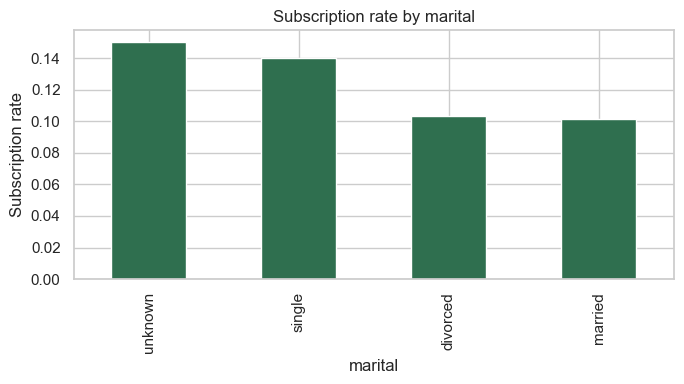

,mean,count
marital,,
unknown,0.150000,80
single,0.140090,11564
divorced,0.103231,4611
married,0.101561,24921


In [7]:
conversion_by('marital')

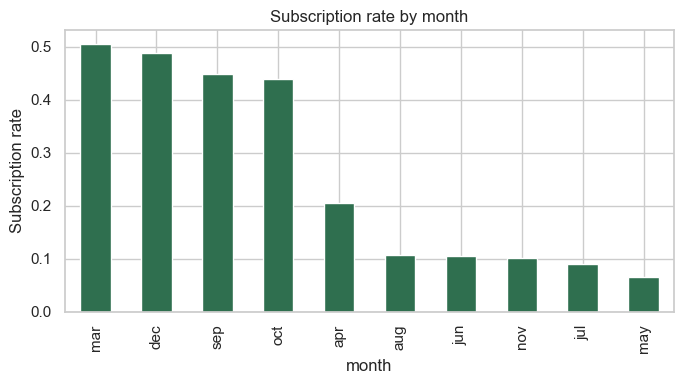

,mean,count
month,,
mar,0.505495,546
dec,0.489011,182
sep,0.449123,570
oct,0.439331,717
apr,0.204865,2631
aug,0.106056,6176
jun,0.105115,5318
nov,0.101463,4100
jul,0.090389,7169


In [8]:
conversion_by('month')

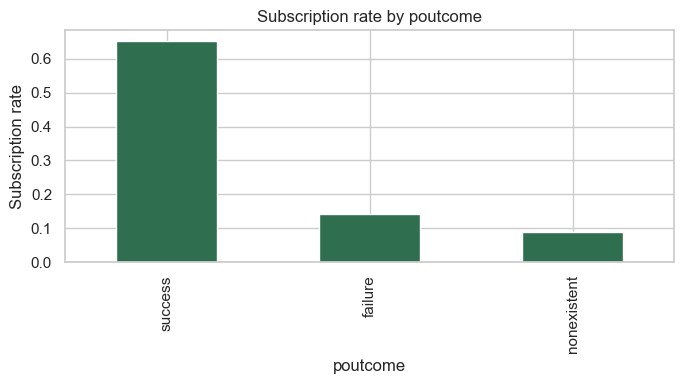

,mean,count
poutcome,,
success,0.651129,1373
failure,0.142286,4252
nonexistent,0.088324,35551


In [9]:
conversion_by('poutcome')

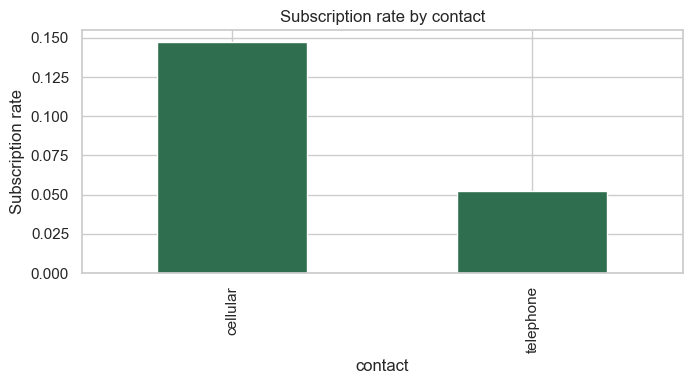

,mean,count
contact,,
cellular,0.147389,26135
telephone,0.052324,15041


In [10]:
conversion_by('contact')

## Numeric feature distributions and correlation
`emp_var_rate`, `euribor3m`, and `nr_employed` are macro-economic indicators
published quarterly/monthly by Banco de Portugal - they move together, so we
expect multicollinearity among them (relevant for the linear model).

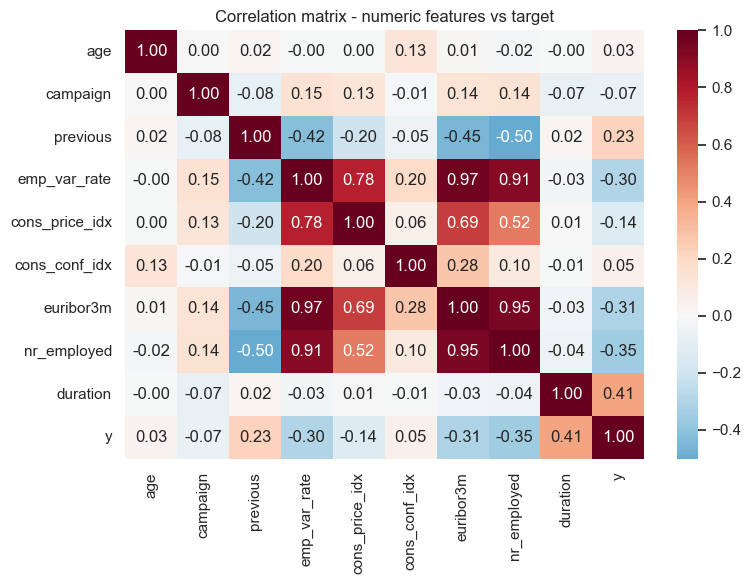

In [11]:
numeric_cols = ['age','campaign','previous','emp_var_rate','cons_price_idx',
                'cons_conf_idx','euribor3m','nr_employed','duration']
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(df[numeric_cols + ['y']].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Correlation matrix - numeric features vs target')
plt.tight_layout()
plt.savefig('../reports/figures/correlation_heatmap.png', dpi=150)
plt.show()

/var/folders/x0/19c93_wd54vb8cy1g6mvp8300000gn/T/ipykernel_8369/2384981002.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['No', 'Yes'])
/var/folders/x0/19c93_wd54vb8cy1g6mvp8300000gn/T/ipykernel_8369/2384981002.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['No', 'Yes'])


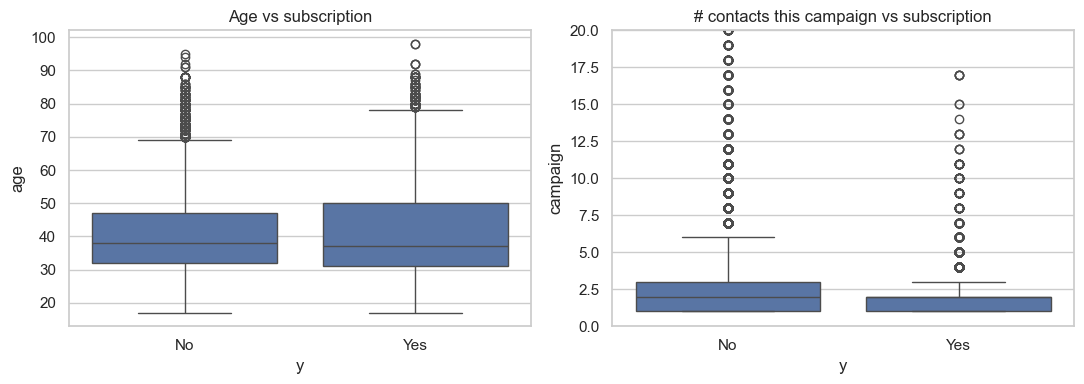

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
sns.boxplot(data=df, x='y', y='age', ax=axes[0])
axes[0].set_xticklabels(['No', 'Yes'])
axes[0].set_title('Age vs subscription')
sns.boxplot(data=df, x='y', y='campaign', ax=axes[1])
axes[1].set_xticklabels(['No', 'Yes'])
axes[1].set_ylim(0, 20)
axes[1].set_title('# contacts this campaign vs subscription')
plt.tight_layout()
plt.savefig('../reports/figures/age_campaign_boxplots.png', dpi=150)
plt.show()

## Key takeaways
- Severe class imbalance (~11% positive) - accuracy alone is a misleading
  metric; ROC-AUC / PR-AUC and recall on the positive class matter more.
- Students and retirees convert far above average, despite being contacted
  less often - a classic under-targeted segment.
- Clients with a successful previous campaign (`poutcome=success`) convert
  at a dramatically higher rate - prior engagement is the single strongest
  behavioral signal.
- Conversion is highly seasonal by month, tracking the bank's own campaign
  calendar and the macro-economic cycle (`emp_var_rate`, `euribor3m`).
- `duration` correlates strongly with `y` by construction (the call has to
  happen for a "yes"), confirming the data dictionary's leakage warning -
  it must be excluded from any prospective targeting model.

See `notebooks/02_feature_engineering.ipynb` and
`notebooks/03_modeling.ipynb` for how these findings shape the feature set
and model design.